# Notebook 10 – Target Variable Analysis
## `10_Target_Analysis.ipynb`

### Learning objectives
- Understand what a target variable is.
- Analyze classification targets using counts, percentages, and class imbalance.
- Analyze regression targets using distribution statistics, skewness, and outliers.
- Explain why target analysis matters before machine learning.

**Important:** Replace `target` below with the actual target column in your dataset. This notebook uses small example datasets so you can run every cell immediately.

## 1. What is a target variable?

A **target variable** is the value a machine-learning model is trained to predict.

- **Classification:** predicts a category, such as `Churn = Yes/No`.
- **Regression:** predicts a numeric value, such as house price or monthly sales.

**Simple example:** Predict whether a student passes or fails. `Pass/Fail` is the target.

**Real-world example:** A hospital predicts whether a patient may be readmitted.

**Business example:** A subscription company predicts which customers may cancel.

**AI/ML use case:** Target values are used as the answers (labels) during supervised learning.

**Why it matters:** If the target is misunderstood, incorrectly encoded, or unreliable, the model can learn the wrong task.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Create example data

This small customer dataset contains:
- `churn`: a classification target (`Yes` or `No`)
- `monthly_spend`: a numeric example target for regression analysis

In a real project, load your own data with `pd.read_csv("your_file.csv")`.

In [2]:
customers = pd.DataFrame({
    "customer_id": range(1, 13),
    "plan": ["Basic", "Basic", "Pro", "Basic", "Pro", "Basic",
             "Pro", "Basic", "Pro", "Basic", "Pro", "Basic"],
    "monthly_spend": [20, 25, 30, 22, 35, 28, 32, 24, 120, 27, 34, 26],
    "churn": ["No", "No", "No", "Yes", "No", "No",
              "Yes", "No", "Yes", "No", "No", "No"]
})
customers

,customer_id,plan,monthly_spend,churn
0,1,Basic,20,No
1,2,Basic,25,No
2,3,Pro,30,No
3,4,Basic,22,Yes
4,5,Pro,35,No
5,6,Basic,28,No
6,7,Pro,32,Yes
7,8,Basic,24,No
8,9,Pro,120,Yes
9,10,Basic,27,No


## 3. Select the target column

Set the target column name to the column you want to predict. Confirm that the column exists before analysis.

In [3]:
classification_target = "churn"
regression_target = "monthly_spend"

print("Classification target:", classification_target)
print("Regression target:", regression_target)
print("Dataset shape:", customers.shape)

Classification target: churn
Regression target: monthly_spend
Dataset shape: (12, 4)


## 4. Classification – class counts

**Class counts** tell us how many rows belong to each category.

**Why selected:** A model cannot be evaluated properly if we do not know how often each class occurs.

**Simple example:** In 10 exam results, 8 students pass and 2 fail.

**Real-world example:** Count how many patients did or did not return to hospital.

**Business example:** Count customers who churned versus customers who stayed.

**AI/ML use case:** Class counts help identify whether a classification dataset may be imbalanced.

In [4]:
class_counts = customers[classification_target].value_counts(dropna=False)
print(class_counts)

churn
No     9
Yes    3
Name: count, dtype: int64


## 5. Classification – class distribution and percentages

A class distribution summarizes how frequently each label occurs. Percentages make class frequencies easier to compare across datasets of different sizes.

**Interpretation:** A much larger percentage for one class may indicate imbalance. The acceptable level depends on the problem and the cost of mistakes.

In [5]:
class_percentages = customers[classification_target].value_counts(normalize=True, dropna=False).mul(100)
class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percentages.round(2)
})
class_summary

,count,percentage
churn,,
No,9,75.0
Yes,3,25.0


## 6. Plot class counts

**Visualization selected:** A count plot directly compares the number of examples in each class.

**Insight to look for:** If one bar is much taller, the target may be imbalanced. This example is small and is for learning, not a production conclusion.

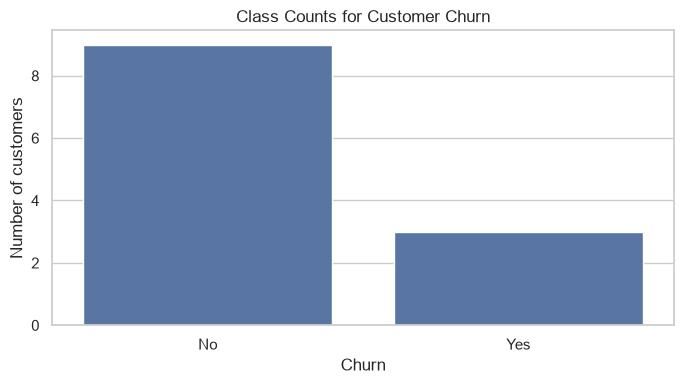

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(data=customers, x=classification_target, order=customers[classification_target].value_counts().index)
plt.title("Class Counts for Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 7. Class imbalance

**Class imbalance** occurs when some target classes have many more examples than others.

**Simple example:** 95 spam-free emails and 5 spam emails.

**Real-world example:** Fraud cases are usually much rarer than legitimate transactions.

**Business example:** Only a small fraction of customers may cancel a subscription.

**AI/ML use case:** Consider stratified train/test splits, suitable metrics (precision, recall, F1, PR-AUC), class weights, or resampling when appropriate.

**Caution:** Do not automatically balance every dataset. First check the business goal, data size, and evaluation metric.

In [7]:
class_ratio = class_counts.max() / class_counts.min()
print("Largest-to-smallest class count ratio:", round(class_ratio, 2))
print("Class percentages:")
print(class_summary["percentage"])

Largest-to-smallest class count ratio: 3.0
Class percentages:
churn
No     75.0
Yes    25.0
Name: percentage, dtype: float64


## 8. Regression – target distribution

A regression target is numeric. Plotting its distribution helps reveal common ranges, skewness, gaps, and extreme values.

**Simple example:** Predict a student's score out of 100.

**Real-world example:** Predict a home's selling price.

**Business example:** Predict daily sales revenue.

**AI/ML use case:** The target distribution can affect the choice of evaluation metrics and whether a justified transformation is worth testing.

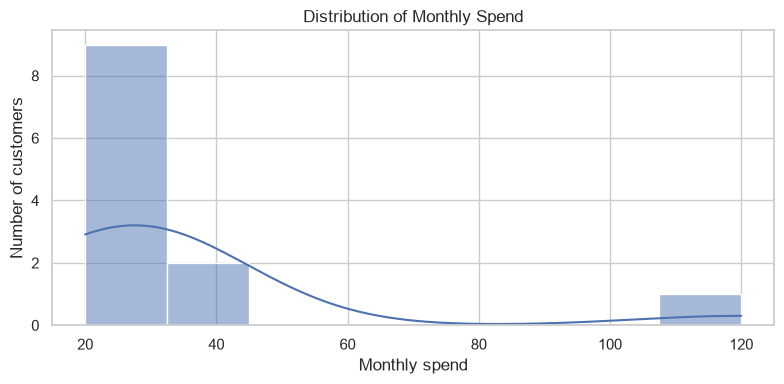

In [8]:
reg_target = customers[regression_target].dropna()

plt.figure(figsize=(8, 4))
sns.histplot(reg_target, kde=True, bins=8)
plt.title("Distribution of Monthly Spend")
plt.xlabel("Monthly spend")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 9. Regression – mean, median, variance, standard deviation, and skewness

- **Mean:** arithmetic average; sensitive to extreme values.
- **Median:** middle value; often more robust to extreme values.
- **Variance:** average squared distance from the mean (sample variance by default in pandas).
- **Standard deviation:** spread measured in the original units.
- **Skewness:** asymmetry of the distribution; positive values often indicate a longer right tail.

**Why it matters:** Comparing mean and median and reviewing spread can expose extreme values or a strongly skewed target.

In [9]:
target_stats = pd.Series({
    "count": reg_target.count(),
    "mean": reg_target.mean(),
    "median": reg_target.median(),
    "sample_variance": reg_target.var(),
    "sample_standard_deviation": reg_target.std(),
    "skewness": reg_target.skew()
})
target_stats

count                         12.000000
mean                          35.250000
median                        27.500000
sample_variance              733.477273
sample_standard_deviation     27.082786
skewness                       3.286431
dtype: float64

## 10. Regression – outlier detection with the IQR rule

The interquartile range (IQR) is Q3 − Q1. A common exploratory rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR.

**Important:** A flagged point is not automatically an error. It may be a valid high-value customer, home, or transaction. Investigate before removing or changing it.

In [10]:
q1 = reg_target.quantile(0.25)
q3 = reg_target.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = reg_target[(reg_target < lower_bound) | (reg_target > upper_bound)]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:")
print(outliers.to_list())

Q1: 24.75
Q3: 32.5
IQR: 7.75
Lower bound: 13.125
Upper bound: 44.125
Potential outliers:
[120]


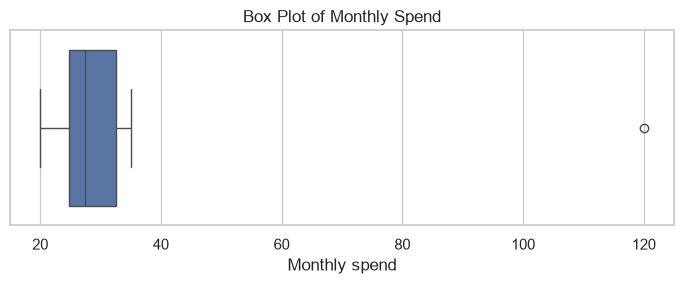

In [11]:
plt.figure(figsize=(7, 3))
sns.boxplot(x=reg_target)
plt.title("Box Plot of Monthly Spend")
plt.xlabel("Monthly spend")
plt.tight_layout()
plt.show()

## 11. Why target analysis is important before Machine Learning

1. It confirms whether the task is classification or regression.
2. It reveals missing or invalid target labels.
3. It identifies class imbalance that may make accuracy misleading.
4. It shows skewness and extreme target values.
5. It helps select useful evaluation metrics.
6. It supports better train/test splitting and preprocessing decisions.
7. It can reveal target leakage risks if target information appears among input features.

### Practical checklist
- [ ] Confirm the target column and its meaning.
- [ ] Check missing and invalid target values.
- [ ] For classification, inspect counts and percentages.
- [ ] For regression, inspect distribution, summary statistics, and outliers.
- [ ] Choose evaluation metrics based on the business problem.
- [ ] Investigate unusual values instead of removing them blindly.